<a href="https://colab.research.google.com/github/anirudhpratapsingh101/ACV_Project/blob/main/Pedestrian_Segmentation_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pedestrian Semantic Segmentation Experiment**
### *Assignment B: Build a Reproducible Segmentation Experiment*

In this project, we implement and evaluate a reproducible binary semantic segmentation experiment on the **Penn-Fudan Pedestrian Dataset**.

We begin by establishing an explicit data contract, training a baseline compact U-Net encoder-decoder, and then applying a single controlled architectural change—introducing **dilated convolution** in the bottleneck—to assess its effect on segmentation accuracy and inference latency under an identical parameter budget.


# **Step 1: Dataset and Data Contract**


Import the required libraries for data loading, neural network construction, training, and evaluation.


In [ ]:
import os
import random
import time
import json
import ssl
import urllib.request
import zipfile
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
import matplotlib.pyplot as plt
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Using device: cuda
GPU: Tesla T4


Download and extract the Penn-Fudan Pedestrian dataset archive.


In [ ]:
data_url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
zip_name = "PennFudanPed.zip"
root_dir = "PennFudanPed"

if not os.path.exists(root_dir):
    print("Downloading Penn-Fudan Pedestrian Dataset...")
    ctx = ssl._create_unverified_context()
    with urllib.request.urlopen(data_url, context=ctx) as r, open(zip_name, "wb") as f:
        f.write(r.read())
    print("Extracting archive...")
    with zipfile.ZipFile(zip_name, "r") as z:
        z.extractall(".")
    print("Download and extraction complete.")
else:
    print("Dataset already available locally.")

img_dir = os.path.join(root_dir, "PNGImages")
mask_dir = os.path.join(root_dir, "PedMasks")

all_files = sorted([f for f in os.listdir(img_dir) if f.endswith(".png")])
print("Total images found in dataset:", len(all_files))


Dataset already available locally.
Total images found in dataset: 170


Split the dataset into training, validation, and holdout test sets using a fixed random seed to guarantee reproducibility.


In [ ]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)

indices = list(range(len(all_files)))
random.shuffle(indices)

train_files = [all_files[i] for i in indices[:108]]
val_files = [all_files[i] for i in indices[108:136]]
test_files = [all_files[i] for i in indices[136:]]

print("Train images :", len(train_files))
print("Val images   :", len(val_files))
print("Test images  :", len(test_files))


Train images : 108
Val images   : 28
Test images  : 34


Visualize an image and its ground-truth mask to inspect the raw annotations before preprocessing.


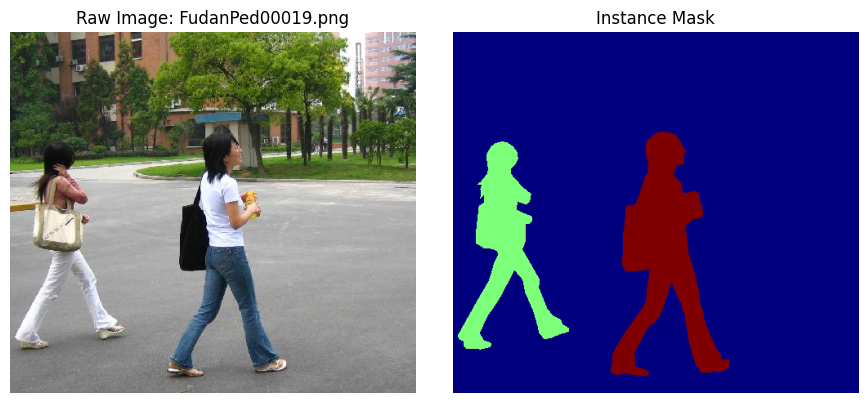

In [ ]:
sample_name = train_files[0]
sample_img = Image.open(os.path.join(img_dir, sample_name)).convert("RGB")
sample_base = os.path.splitext(sample_name)[0]
sample_mask = Image.open(os.path.join(mask_dir, f"{sample_base}_mask.png"))

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(sample_img)
ax[0].set_title(f"Raw Image: {sample_name}")
ax[0].axis("off")

ax[1].imshow(sample_mask, cmap="jet")
ax[1].set_title("Instance Mask")
ax[1].axis("off")
plt.tight_layout()
plt.show()


For this experiment, we have selected the **Penn-Fudan Pedestrian Dataset**, an annotated public benchmark containing urban campus scenes, to perform **binary semantic segmentation**.

A fixed random seed of **42** is used to ensure full reproducibility of the train-validation-test split across different runs. The dataset consists of 170 images: 136 images are used for training and validation (split into **108 training images (~80%)** and **28 validation images (~20%)**), while **34 images (20%)** are held out strictly for final test evaluation.

In the ground-truth segmentation masks, pixels corresponding to pedestrians are assigned class ID **1**, and background pixels are assigned class ID **0**. All input images and masks are resized to a standard resolution of **160 × 160 pixels**. **Bilinear interpolation** is used for resizing images to maintain smooth gradients, whereas **nearest-neighbor interpolation** is applied to masks to keep integer class labels discrete without introducing interpolation artifacts. Additionally, **random horizontal flipping ($p = 0.5$)** is applied as data augmentation only during training. These preprocessing steps are held constant across both the baseline and modified models to ensure a fair and controlled comparison.


# **Step 2: Data Preprocessing and DataLoader Creation**


Create a custom Dataset class that handles image resizing, converting instance masks into binary semantic labels, and applying data augmentation.


In [ ]:
IMG_SIZE = 160

class PedDataset(Dataset):
    def __init__(self, files, images_dir, masks_dir, augment=False):
        self.files = files
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.augment = augment

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        filename = self.files[idx]
        image_path = os.path.join(self.images_dir, filename)
        base_name = os.path.splitext(filename)[0]
        mask_path = os.path.join(self.masks_dir, f"{base_name}_mask.png")

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path)

        # Bilinear for image, Nearest-neighbor for mask
        image = TF.resize(image, [IMG_SIZE, IMG_SIZE], interpolation=InterpolationMode.BILINEAR)
        mask = TF.resize(mask, [IMG_SIZE, IMG_SIZE], interpolation=InterpolationMode.NEAREST)

        # Augmentation on training data only
        if self.augment and random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        image = TF.to_tensor(image)

        # Convert instance mask to binary semantic mask (0 = Background, 1 = Pedestrian)
        mask_arr = np.array(mask)
        binary_mask = (mask_arr > 0).astype(np.int64)
        mask_tensor = torch.from_numpy(binary_mask)

        return image, mask_tensor


Apply preprocessing to our dataset splits.


In [ ]:
train_ds = PedDataset(train_files, img_dir, mask_dir, augment=True)
val_ds = PedDataset(val_files, img_dir, mask_dir, augment=False)
test_ds = PedDataset(test_files, img_dir, mask_dir, augment=False)

print("Processed training samples   :", len(train_ds))
print("Processed validation samples :", len(val_ds))
print("Processed testing samples    :", len(test_ds))


Processed training samples   : 108
Processed validation samples : 28
Processed testing samples    : 34


Create DataLoaders for batching and shuffling.


In [ ]:
BATCH_SIZE = 8

def make_loaders(seed=SEED):
    set_seed(seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(SEED)

print("Training batches   :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Testing batches    :", len(test_loader))


Training batches   : 14
Validation batches : 4
Testing batches    : 5


Verify that our DataLoader outputs correct batch shapes and value ranges.


In [ ]:
sample_images, sample_masks = next(iter(train_loader))
print("Batch images shape :", sample_images.shape)
print("Batch masks shape  :", sample_masks.shape)
print("Image value range  :", f"[{sample_images.min():.2f}, {sample_images.max():.2f}]")
print("Unique mask values :", torch.unique(sample_masks).tolist())


Batch images shape : torch.Size([8, 3, 160, 160])
Batch masks shape  : torch.Size([8, 160, 160])
Image value range  : [0.00, 1.00]
Unique mask values : [0, 1]


Visualize the processed image and corresponding binary mask.


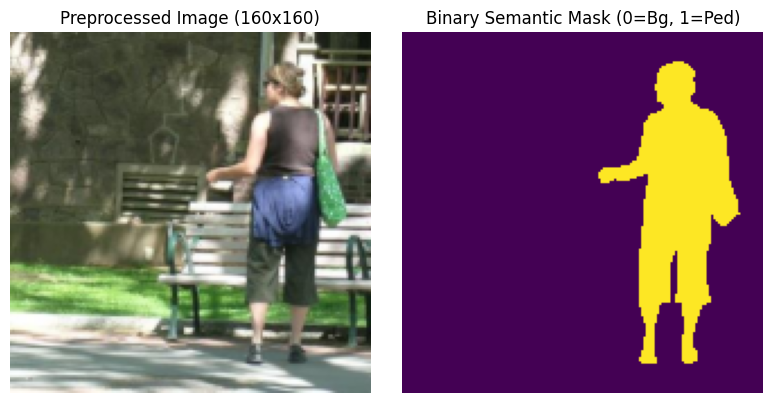

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample_images[0].permute(1, 2, 0).numpy())
axes[0].set_title("Preprocessed Image (160x160)")
axes[0].axis("off")

axes[1].imshow(sample_masks[0].numpy(), cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Binary Semantic Mask (0=Bg, 1=Ped)")
axes[1].axis("off")
plt.tight_layout()
plt.show()


# **Step 3: Implementing the Baseline U-Net Model**

U-Net consists of three major components:
1. **Encoder (Contracting Path):** Extracts hierarchical features while reducing spatial resolution using pooling.
2. **Bottleneck:** Processes the deepest features, capturing broader semantic context.
3. **Decoder (Expanding Path):** Upsamples features back to original resolution and merges high-resolution skip connections from the encoder to retain precise boundaries.


Implement the Double Convolution Block.


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels, kernel_size=3,
                padding=dilation, dilation=dilation, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels, out_channels, kernel_size=3,
                padding=dilation, dilation=dilation, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


Implement the complete U-Net architecture with skip connections.


In [ ]:
class PedUNet(nn.Module):
    def __init__(self, num_classes=2, bottleneck_dilation=1):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.pool = nn.MaxPool2d(2, 2)

        # Bottleneck
        self.bottleneck = ConvBlock(64, 128, dilation=bottleneck_dilation)

        # Decoder
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(128, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(64, 32)

        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(32, 16)

        # Output classification head
        self.head = nn.Conv2d(16, num_classes, kernel_size=1)

    def forward(self, x):
        # Contracting path
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Expanding path with skip connections
        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.head(d1)


Initialize our baseline model with `bottleneck_dilation = 1`.


In [ ]:
set_seed(SEED)
baseline_model = PedUNet(num_classes=2, bottleneck_dilation=1).to(device)
print("Baseline model created successfully!")


Baseline model created successfully!


Check whether our model produces the expected output dimensions on a sample batch.


In [ ]:
with torch.no_grad():
    sample_preds = baseline_model(sample_images.to(device))
    print("Input batch shape  :", sample_images.shape)
    print("Output batch shape :", sample_preds.shape)


Input batch shape  : torch.Size([8, 3, 160, 160])
Output batch shape : torch.Size([8, 2, 160, 160])


Calculate the number of trainable parameters in the baseline network.


In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline_params = count_parameters(baseline_model)
print("Baseline trainable parameters:", f"{baseline_params:,}")


Baseline trainable parameters: 482,754


# **Step 4: Training the Baseline U-Net Model**


Define the training hyperparameters.


In [ ]:
LEARNING_RATE = 0.001
NUM_EPOCHS = 12
print("Device        :", device)
print("Learning rate :", LEARNING_RATE)
print("Epochs        :", NUM_EPOCHS)
print("Batch size    :", BATCH_SIZE)


Device        : cuda
Learning rate : 0.001
Epochs        : 12
Batch size    : 8


Define the loss function and optimizer.


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

print("Loss function :", criterion)
print("Optimizer     :", optimizer.__class__.__name__)


Loss function : CrossEntropyLoss()
Optimizer     : Adam


Write the training function for a single epoch.


In [ ]:
def train_one_epoch(model, loader, opt, crit):
    model.train()
    total_loss = 0.0
    total_pixels = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        opt.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = crit(outputs, masks)
        loss.backward()
        opt.step()

        cnt = masks.numel()
        total_loss += loss.item() * cnt
        total_pixels += cnt

    return total_loss / total_pixels


Write the validation function.


In [ ]:
@torch.no_grad()
def validate_one_epoch(model, loader, crit):
    model.eval()
    total_loss = 0.0
    total_pixels = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        loss = crit(outputs, masks)

        cnt = masks.numel()
        total_loss += loss.item() * cnt
        total_pixels += cnt

    return total_loss / total_pixels


Train our baseline U-Net, logging progress and saving the best checkpoint based on validation loss.


In [ ]:
train_losses = []
val_losses = []
best_val_loss = float("inf")
best_epoch = 0

print("Starting baseline model training...")
for epoch in range(NUM_EPOCHS):
    tr_loss = train_one_epoch(baseline_model, train_loader, optimizer, criterion)
    vl_loss = validate_one_epoch(baseline_model, val_loader, criterion)

    train_losses.append(tr_loss)
    val_losses.append(vl_loss)

    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | Train Loss: {tr_loss:.4f} | Val Loss: {vl_loss:.4f}")

    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        best_epoch = epoch + 1
        torch.save({
            "epoch": best_epoch,
            "model_state_dict": baseline_model.state_dict(),
            "val_loss": best_val_loss,
            "bottleneck_dilation": 1
        }, "baseline_best.pth")


print("Baseline training completed!")
print("Best epoch           :", best_epoch)
print("Best validation loss :", f"{best_val_loss:.4f}")


Starting baseline model training...
Epoch [01/12] | Train Loss: 0.5041 | Val Loss: 0.5009
Epoch [02/12] | Train Loss: 0.3973 | Val Loss: 0.4468
Epoch [03/12] | Train Loss: 0.3465 | Val Loss: 0.3664
Epoch [04/12] | Train Loss: 0.3085 | Val Loss: 0.3230
Epoch [05/12] | Train Loss: 0.2877 | Val Loss: 0.3112
Epoch [06/12] | Train Loss: 0.2673 | Val Loss: 0.3093
Epoch [07/12] | Train Loss: 0.2508 | Val Loss: 0.2786
Epoch [08/12] | Train Loss: 0.2379 | Val Loss: 0.2510
Epoch [09/12] | Train Loss: 0.2157 | Val Loss: 0.2380
Epoch [10/12] | Train Loss: 0.2094 | Val Loss: 0.2323
Epoch [11/12] | Train Loss: 0.1948 | Val Loss: 0.2363
Epoch [12/12] | Train Loss: 0.1924 | Val Loss: 0.2244
Baseline training completed!
Best epoch           : 12
Best validation loss : 0.2244


Plot training and validation loss curves for the baseline model.


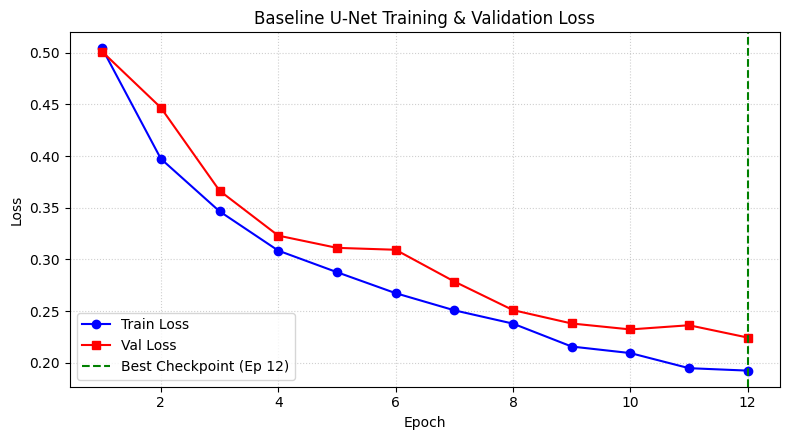

In [ ]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, "b-o", label="Train Loss")
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, "r-s", label="Val Loss")
plt.axvline(best_epoch, color="green", linestyle="--", label=f"Best Checkpoint (Ep {best_epoch})")
plt.title("Baseline U-Net Training & Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("baseline_loss_curve.png", dpi=150)
plt.show()


Load the best saved baseline model checkpoint for subsequent evaluation.


In [ ]:
checkpoint = torch.load("baseline_best.pth", map_location=device, weights_only=True)
baseline_model.load_state_dict(checkpoint["model_state_dict"])
baseline_model.eval()

print("Best baseline model loaded successfully!")
print("Selected epoch  :", checkpoint["epoch"])
print("Validation loss :", f"{checkpoint['val_loss']:.4f}")


Best baseline model loaded successfully!
Selected epoch  : 12
Validation loss : 0.2244


# **Step 5: Modify the U-Net Architecture (Controlled Experiment)**

**What are we changing?**  
We introduce **dilated convolution** in the bottleneck of our U-Net. In standard convolution ($r=1$), a $3 	imes 3$ kernel processes nine adjacent spatial positions. When the dilation rate is increased to $r=2$, the kernel samples positions spaced farther apart, effectively covering a $5 	imes 5$ spatial receptive field while still utilizing exactly nine kernel weights per channel pair.

This allows the deepest layer of the network to aggregate context over a larger area of the image without increasing the parameter count.

**Research Question:**  
*Does using `dilation = 2` in the bottleneck improve pedestrian segmentation compared with the baseline U-Net (`dilation = 1`), while keeping all other settings identical?*


Create the modified U-Net and re-seed the data loaders to ensure identical data ordering.


In [ ]:
set_seed(SEED)
mod_train_loader, mod_val_loader, mod_test_loader = make_loaders(SEED)

modified_model = PedUNet(num_classes=2, bottleneck_dilation=2).to(device)
print("Modified U-Net created successfully!")
print("Bottleneck dilation:", 2)


Modified U-Net created successfully!
Bottleneck dilation: 2


Compare the number of parameters between baseline and modified models to confirm zero parameter overhead.


In [ ]:
modified_params = count_parameters(modified_model)

print("Baseline parameters :", f"{baseline_params:,}")
print("Modified parameters :", f"{modified_params:,}")
print("Parameter difference:", modified_params - baseline_params)

assert baseline_params == modified_params, "Error: parameter counts must be identical for a controlled comparison!"


Baseline parameters : 482,754
Modified parameters : 482,754
Parameter difference: 0


Configure the optimizer and loss function for the modified model.


In [ ]:
mod_criterion = nn.CrossEntropyLoss()
mod_optimizer = optim.Adam(modified_model.parameters(), lr=LEARNING_RATE)


Train the modified U-Net under identical conditions.


In [ ]:
mod_train_losses = []
mod_val_losses = []
mod_best_val_loss = float("inf")
mod_best_epoch = 0

print("Starting modified model training...")
for epoch in range(NUM_EPOCHS):
    tr_loss = train_one_epoch(modified_model, mod_train_loader, mod_optimizer, mod_criterion)
    vl_loss = validate_one_epoch(modified_model, mod_val_loader, mod_criterion)

    mod_train_losses.append(tr_loss)
    mod_val_losses.append(vl_loss)

    print(f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | Train Loss: {tr_loss:.4f} | Val Loss: {vl_loss:.4f}")

    if vl_loss < mod_best_val_loss:
        mod_best_val_loss = vl_loss
        mod_best_epoch = epoch + 1
        torch.save({
            "epoch": mod_best_epoch,
            "model_state_dict": modified_model.state_dict(),
            "val_loss": mod_best_val_loss,
            "bottleneck_dilation": 2
        }, "modified_best.pth")

print("Modified model training completed!")
print("Best epoch           :", mod_best_epoch)
print("Best validation loss :", f"{mod_best_val_loss:.4f}")

# Reload best checkpoint
mod_cp = torch.load("modified_best.pth", map_location=device, weights_only=True)
modified_model.load_state_dict(mod_cp["model_state_dict"])
modified_model.eval()


Starting modified model training...
Epoch [01/12] | Train Loss: 0.4982 | Val Loss: 0.5022
Epoch [02/12] | Train Loss: 0.3811 | Val Loss: 0.4098
Epoch [03/12] | Train Loss: 0.3384 | Val Loss: 0.3563
Epoch [04/12] | Train Loss: 0.2991 | Val Loss: 0.3076
Epoch [05/12] | Train Loss: 0.2728 | Val Loss: 0.3045
Epoch [06/12] | Train Loss: 0.2517 | Val Loss: 0.2791
Epoch [07/12] | Train Loss: 0.2378 | Val Loss: 0.2618
Epoch [08/12] | Train Loss: 0.2317 | Val Loss: 0.2912
Epoch [09/12] | Train Loss: 0.2092 | Val Loss: 0.2398
Epoch [10/12] | Train Loss: 0.1968 | Val Loss: 0.2313
Epoch [11/12] | Train Loss: 0.1877 | Val Loss: 0.2204
Epoch [12/12] | Train Loss: 0.1782 | Val Loss: 0.2289
Modified model training completed!
Best epoch           : 11
Best validation loss : 0.2204


PedUNet(
  (enc1): ConvBlock(
    (conv): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): ConvBlock(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  

Compare the loss curves of both models to observe convergence behavior.


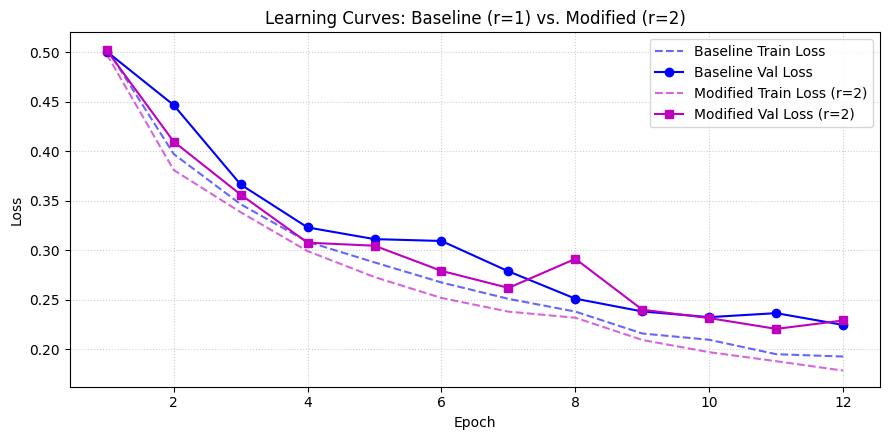

In [ ]:
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, "b--", alpha=0.6, label="Baseline Train Loss")
plt.plot(range(1, NUM_EPOCHS + 1), val_losses, "b-o", label="Baseline Val Loss")
plt.plot(range(1, NUM_EPOCHS + 1), mod_train_losses, "m--", alpha=0.6, label="Modified Train Loss (r=2)")
plt.plot(range(1, NUM_EPOCHS + 1), mod_val_losses, "m-s", label="Modified Val Loss (r=2)")
plt.title("Learning Curves: Baseline (r=1) vs. Modified (r=2)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("loss_curves_comparison.png", dpi=150)
plt.show()


# **Step 6: Evaluate and Compare Both U-Net Models**


Write the IoU evaluation function to compute per-class IoU (Background and Pedestrian) and Mean IoU (mIoU) on the holdout test set.


In [ ]:
@torch.inference_mode()
def evaluate_iou(model, loader):
    model.eval()
    confusion = torch.zeros((2, 2), dtype=torch.int64)
    per_image_ped_iou = []

    for batch_i, (images, masks) in enumerate(loader):
        images = images.to(device)
        masks = masks.to(device)

        preds = model(images).argmax(dim=1)

        for i in range(images.size(0)):
            m = masks[i]
            p = preds[i]

            tp = ((p == 1) & (m == 1)).sum().item()
            fp = ((p == 1) & (m == 0)).sum().item()
            fn = ((p == 0) & (m == 1)).sum().item()
            denom = tp + fp + fn
            iou = tp / denom if denom > 0 else 1.0

            img_idx = batch_i * loader.batch_size + i
            per_image_ped_iou.append((img_idx, iou))

            for actual in range(2):
                for pred in range(2):
                    confusion[actual, pred] += ((m == actual) & (p == pred)).sum().item()

    ious = []
    for c in range(2):
        tp = confusion[c, c].item()
        fp = confusion[:, c].sum().item() - tp
        fn = confusion[c, :].sum().item() - tp
        ious.append(tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0.0)

    return {
        "background_iou": ious[0],
        "pedestrian_iou": ious[1],
        "miou": (ious[0] + ious[1]) / 2.0,
        "per_image_ped_iou": per_image_ped_iou
    }


Evaluate both models on the unseen holdout test dataset.


In [ ]:
baseline_results = evaluate_iou(baseline_model, test_loader)
modified_results = evaluate_iou(modified_model, test_loader)

print("Baseline Background IoU :", f"{baseline_results['background_iou']:.4f}")
print("Baseline Pedestrian IoU :", f"{baseline_results['pedestrian_iou']:.4f}")
print("Baseline mIoU           :", f"{baseline_results['miou']:.4f}")
print("-" * 40)
print("Modified Background IoU :", f"{modified_results['background_iou']:.4f}")
print("Modified Pedestrian IoU :", f"{modified_results['pedestrian_iou']:.4f}")
print("Modified mIoU           :", f"{modified_results['miou']:.4f}")


Baseline Background IoU : 0.9144
Baseline Pedestrian IoU : 0.5981
Baseline mIoU           : 0.7562
----------------------------------------
Modified Background IoU : 0.9126
Modified Pedestrian IoU : 0.5740
Modified mIoU           : 0.7433


Benchmark inference latency under strict measurement conditions (10 warm-up runs, 50 timed forward passes).


In [ ]:
def measure_latency(model, runs=50, warmup=10):
    model.eval()
    dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)

    with torch.inference_mode():
        for _ in range(warmup):
            _ = model(dummy_input)
        if device.type == "cuda":
            torch.cuda.synchronize()

        times = []
        for _ in range(runs):
            t0 = time.perf_counter()
            _ = model(dummy_input)
            if device.type == "cuda":
                torch.cuda.synchronize()
            times.append((time.perf_counter() - t0) * 1000)

    return {
        "median_ms": float(np.median(times)),
        "p95_ms": float(np.percentile(times, 95))
    }

baseline_latency = measure_latency(baseline_model)
modified_latency = measure_latency(modified_model)

print("Baseline Latency : Median =", f"{baseline_latency['median_ms']:.2f} ms | P95 =", f"{baseline_latency['p95_ms']:.2f} ms")
print("Modified Latency : Median =", f"{modified_latency['median_ms']:.2f} ms | P95 =", f"{modified_latency['p95_ms']:.2f} ms")


Baseline Latency : Median = 2.53 ms | P95 = 2.64 ms
Modified Latency : Median = 2.07 ms | P95 = 2.61 ms


Final Quantitative Comparison Table showing all required submission metrics.


In [ ]:
comparison = pd.DataFrame({
    "Metric": [
        "Background IoU",
        "Pedestrian IoU",
        "mIoU",
        "Trainable Parameters",
        "Median Latency (ms)",
        "P95 Latency (ms)"
    ],
    "Baseline U-Net": [
        f"{baseline_results['background_iou']:.4f}",
        f"{baseline_results['pedestrian_iou']:.4f}",
        f"{baseline_results['miou']:.4f}",
        f"{baseline_params:,}",
        f"{baseline_latency['median_ms']:.2f}",
        f"{baseline_latency['p95_ms']:.2f}"
    ],
    "Modified U-Net": [
        f"{modified_results['background_iou']:.4f}",
        f"{modified_results['pedestrian_iou']:.4f}",
        f"{modified_results['miou']:.4f}",
        f"{modified_params:,}",
        f"{modified_latency['median_ms']:.2f}",
        f"{modified_latency['p95_ms']:.2f}"
    ]
})

print(comparison.to_string(index=False))
comparison.to_csv("model_comparison.csv", index=False)


              Metric Baseline U-Net Modified U-Net
      Background IoU         0.9144         0.9126
      Pedestrian IoU         0.5981         0.5740
                mIoU         0.7562         0.7433
Trainable Parameters        482,754        482,754
 Median Latency (ms)           2.53           2.07
    P95 Latency (ms)           2.64           2.61


Visualizing predictions of both models alongside ground truth masks on test images.


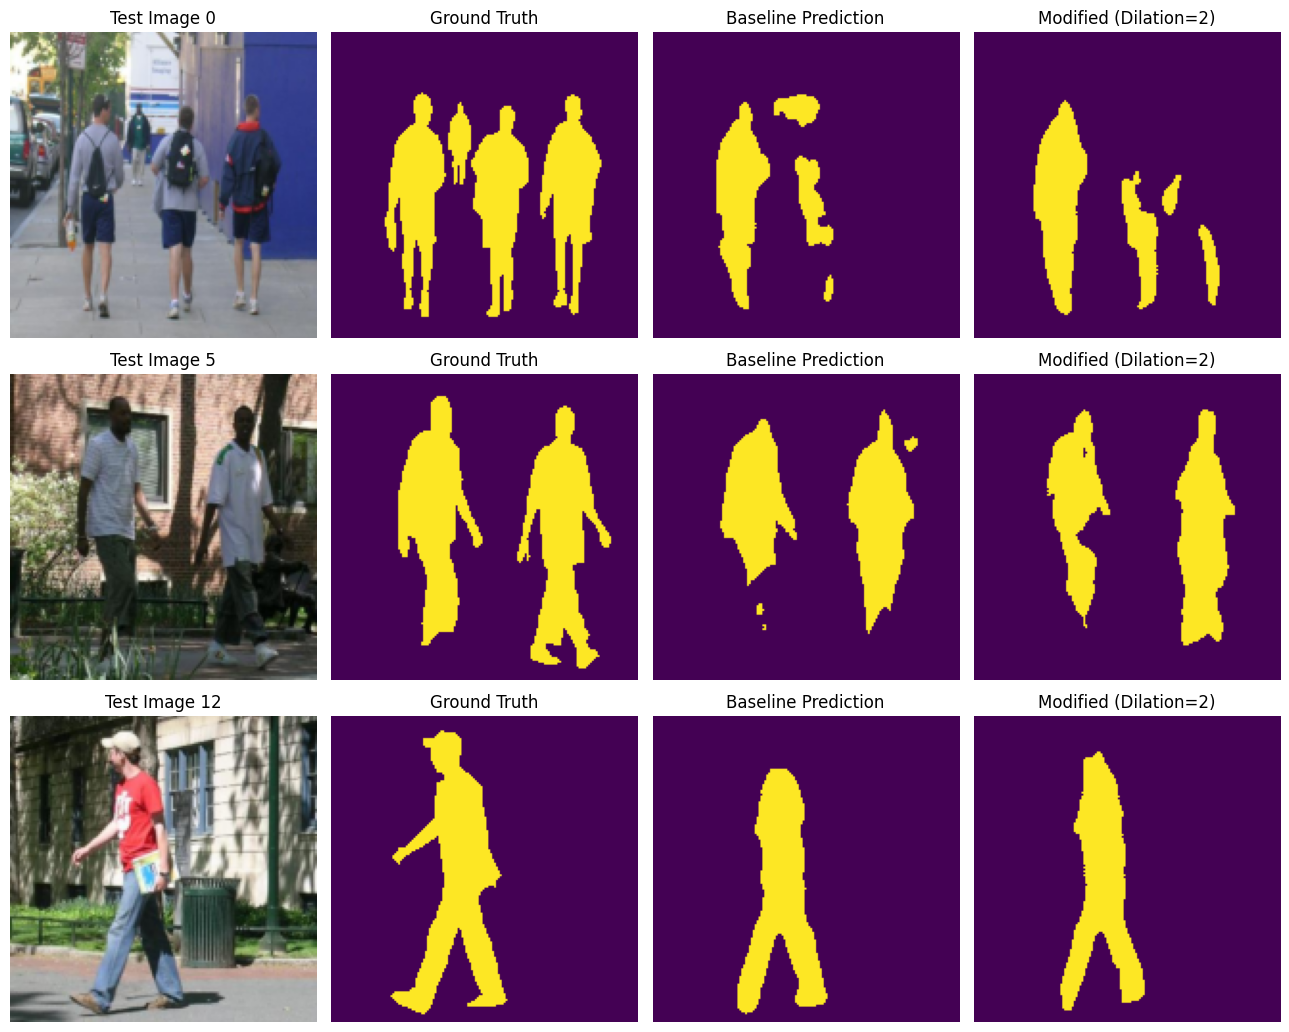

In [ ]:
def visualize_comparison(indices, save_path="segmentation_comparison.png"):
    fig, axes = plt.subplots(len(indices), 4, figsize=(13, 3.5 * len(indices)), squeeze=False)

    for row, idx in enumerate(indices):
        image, mask = test_ds[idx]
        inp = image.unsqueeze(0).to(device)

        with torch.inference_mode():
            base_pred = baseline_model(inp).argmax(dim=1).squeeze().cpu().numpy()
            mod_pred = modified_model(inp).argmax(dim=1).squeeze().cpu().numpy()

        axes[row, 0].imshow(image.permute(1, 2, 0).cpu().numpy())
        axes[row, 0].set_title(f"Test Image {idx}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(mask.cpu().numpy(), cmap="viridis", vmin=0, vmax=1)
        axes[row, 1].set_title("Ground Truth")
        axes[row, 1].axis("off")

        axes[row, 2].imshow(base_pred, cmap="viridis", vmin=0, vmax=1)
        axes[row, 2].set_title("Baseline Prediction")
        axes[row, 2].axis("off")

        axes[row, 3].imshow(mod_pred, cmap="viridis", vmin=0, vmax=1)
        axes[row, 3].set_title("Modified (Dilation=2)")
        axes[row, 3].axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()

# Visualize 3 diverse test images
visualize_comparison([0, 5, 12])


Identify failure cases by sorting test images by pedestrian IoU to inspect where and why errors occurred.


Lowest baseline segmentation cases:
Test image 27: Pedestrian IoU = 0.2189
Test image 32: Pedestrian IoU = 0.2942
Test image 0: Pedestrian IoU = 0.3173


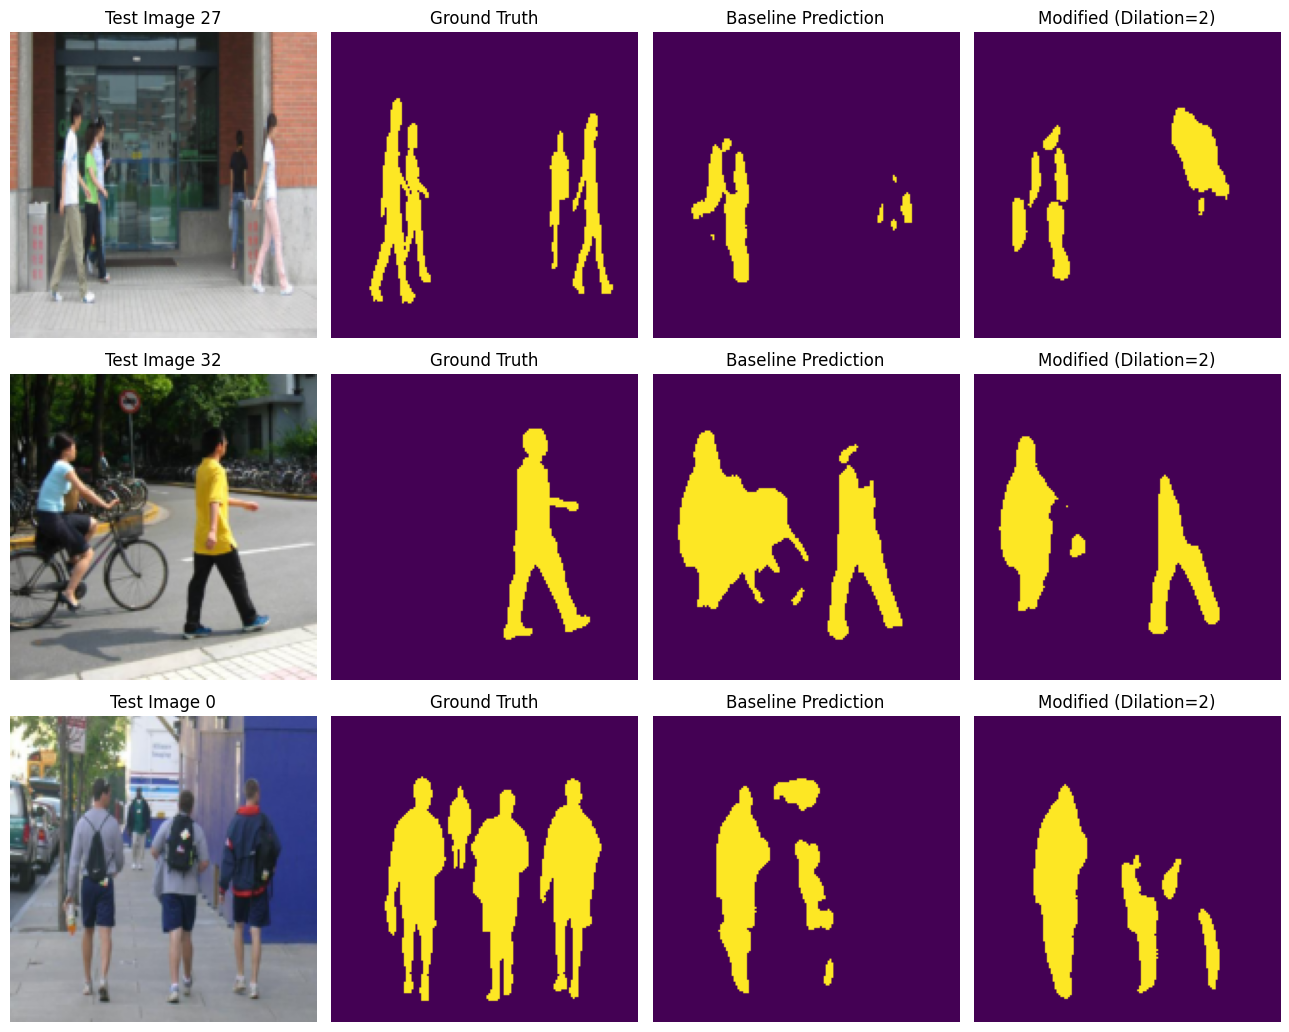

In [ ]:
worst_cases = sorted(baseline_results["per_image_ped_iou"], key=lambda x: x[1])[:3]

print("Lowest baseline segmentation cases:")
for idx, iou in worst_cases:
    print(f"Test image {idx}: Pedestrian IoU = {iou:.4f}")

worst_indices = [idx for idx, _ in worst_cases]
visualize_comparison(worst_indices, save_path="failure_cases.png")


Save full evaluation summary to JSON and prepare download helper for Google Colab.


In [ ]:
evaluation_summary = {
    "dataset": "Penn-Fudan Pedestrian",
    "test_images": len(test_ds),
    "image_resolution": [IMG_SIZE, IMG_SIZE],
    "seed": SEED,
    "baseline": {
        "background_iou": baseline_results["background_iou"],
        "pedestrian_iou": baseline_results["pedestrian_iou"],
        "miou": baseline_results["miou"],
        "parameters": baseline_params,
        "latency": baseline_latency
    },
    "modified": {
        "background_iou": modified_results["background_iou"],
        "pedestrian_iou": modified_results["pedestrian_iou"],
        "miou": modified_results["miou"],
        "parameters": modified_params,
        "latency": modified_latency
    }
}

with open("evaluation_results.json", "w") as f:
    json.dump(evaluation_summary, f, indent=4)

print("Evaluation results saved to 'evaluation_results.json' successfully!")

# Optional: download in Google Colab
try:
    from google.colab import files
    for fn in ["model_comparison.csv", "evaluation_results.json", "baseline_loss_curve.png", "loss_curves_comparison.png", "segmentation_comparison.png", "failure_cases.png"]:
        if os.path.exists(fn):
            files.download(fn)
except ImportError:
    pass


Evaluation results saved to 'evaluation_results.json' successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>